In [154]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"
if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"



# INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory 
try:
    new_dir = pathlib.Path(FIG_DIR+'/snowfall_rate/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass




mimi.uio.no


In [155]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [156]:
# import packages
from imports import (np, plt, xr, glob, pd, BoundaryNorm, cm, sns, LinearSegmentedColormap, set_context, WindroseAxes, Wedge, Patch, Line2D, date2num, DateFormatter,)
import functions as fct



In [157]:
# reload imports
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [158]:
# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [159]:
particle_vars = [
        'aggregate',
        'graupel',
        'pristine'
    ]
var_names = np.concatenate((np.array(['wind_direction', 'air_temperature', 'wind_speed', 'precipitation', 'Ze', 'W', 'spectralWidth', 'most_common_class']), np.array(particle_vars)))

loc = 'HATPRO_Airport_10min'

In [160]:

# Combine HATPRO 10 min averaged temperature and Airport 10 min wind data
dsx = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'10min_filled_obs_hatpro_airport_*ANX_2023*.nc'))))
# substitute the wind direction and speed and remove the variable *_filled*
dsx['wind_direction'] = dsx['wind_direction_filled'].copy()
dsx['wind_speed'] = dsx['wind_speed_filled'].copy()
dsx = dsx.drop_vars(["wind_direction_filled", "wind_speed_filled"],)



### previous seperation into "CAO", "WAI" and "undefined" was too complicated and led to inconsistency

- the clearest signal appears, when focusing on 
  - **southerly and southeasterly wind** (dominated by aggregate)
  - **southwest to east wind** (dominated by graupel)
  - alternative 
    - **southwest and westerly wind** (dominated by graupel >60%)
    - **northwesterly to easterly wind** (dominated by graupel >70%)

- Proposed simpler categorization
  - southerly/southeasterly flow (e.g. 112.5° - 202.5°): **aggregate** dominated &rarr; call this "WAI"
  - northwesterly/easterly flow (e.g. 0 - 112.5°, 292.5° - 360°): **graupel** dominated &rarr; call this "marine" or "CAO"
  - southwesterly/westerly flow (e.g. 202.5° - 292.5°): **somewhat graupel** dominated &rarr; call this "other"
  - keep it *based on WD only*, not temperature


In [161]:
cao_wd_condition = ((dsx['wind_direction'] < 112.5) | 
                    # (dsx['wind_direction'] >= 202.5)).compute()
                    (dsx['wind_direction'] >= 292.5)).compute()

wai_wd_condition = ((dsx['wind_direction'] >= 112.5) & 
                    (dsx['wind_direction'] < 202.5)).compute()
    
other_wd_condition = ((dsx['wind_direction'] >= 202.5) &
                      (dsx['wind_direction'] < 292.5)).compute()


# Combine logical masks
cao_mask = cao_wd_condition #& cao_2t_condition
wai_mask = wai_wd_condition #& wai_2t_condition
other_mask = other_wd_condition
    
for var in var_names:
    if var in dsx:
        dsx[var+'_marine'] = dsx[var].where(cao_mask, drop=True)
        dsx[var+'_wai'] = dsx[var].where(wai_mask, drop=True)
        dsx[var+'_other'] = dsx[var].where(other_mask, drop=True)
        
        # print(f"{loc}, {var}, All: {dsx[var].count().values}, CAO: {dsx[var+'_marine'].count().values}, WAI: {dsx[var+'_wai'].count().values}, Undef: {dsx[var+'_other'].count().values}")
        print(f"{loc}, {var}, All: {dsx[var].count().values}, CAO: {dsx[var+'_marine'].count().values}, WAI: {dsx[var+'_wai'].count().values}")




HATPRO_Airport_10min, wind_direction, All: 42900, CAO: 13687, WAI: 13600
HATPRO_Airport_10min, air_temperature, All: 30152, CAO: 9575, WAI: 8815
HATPRO_Airport_10min, wind_speed, All: 42900, CAO: 13687, WAI: 13600
HATPRO_Airport_10min, precipitation, All: 672, CAO: 220, WAI: 211
HATPRO_Airport_10min, Ze, All: 249516, CAO: 54199, WAI: 54348
HATPRO_Airport_10min, W, All: 249516, CAO: 54199, WAI: 54348
HATPRO_Airport_10min, spectralWidth, All: 249456, CAO: 54194, WAI: 54335
HATPRO_Airport_10min, most_common_class, All: 27360, CAO: 9934, WAI: 7556


### Use the empirical Ze-S relationship as given in 
Maahn, M. and Kollias, P.: Improved Micro Rain Radar snow measurements using Doppler spectra post-processing, Atmos. Meas. Tech., 5, 2661–2673, https://doi.org/10.5194/amt-5-2661-2012, 2012. 

$$ Ze = 56 \cdot S^{1.2}  \rightarrow S = \left(\frac{Ze}{56}\right)^{1/1.2}$$

assume Ze in $mm^6/m^3$ to get from [dBz] to [$mm^6/m^3$]

$$Ze [dBz] = 10 \cdot log_{10}(Ze [mm^6/m^3])$$
$$\rightarrow Ze [mm^6/m^3] = 10 ^{dBz/10}$$

In [162]:
# Convert Ze (dBz) to snowfall rate (S)
def ze_to_snowfall_rate(Ze_dbz):
    # Ze to linear units
    Ze_lin = 10 ** (Ze_dbz /10)
    # Apply Z-S relationship
    S = (Ze_lin / 56) ** (1/1.2)                # Matrosov (2007) - aggregate snowflakes
    S_bracci = (Ze_lin / 134) ** (1/1.25)       # Bracci et al. (2021) - aggregate
    S_nakai_a = (Ze_lin / 107.4) ** (1/1.67)    # Nakai et al. (2021) - heavily rimed aggregate
    S_nakai_g = (Ze_lin / 227.4) ** (1/1.67)    # Nakai et al. (2021) - graupel
    S_pu = (Ze_lin / 252) ** (1/2.03)           # Pu et al. (2020) - graupel


    # convert rate per minute to mm/h
    S = (S/60).resample(time='1H').sum()
    S_bracci = (S_bracci/60).resample(time='1H').sum()
    S_nakai_a = (S_nakai_a/60).resample(time='1H').sum()
    S_nakai_g = (S_nakai_g/60).resample(time='1H').sum()
    S_pu = (S_pu/60).resample(time='1H').sum()
    
    df1 = S.isel(range=3).drop('range').rename('Matrosov_aggregate').to_dataframe()
    df2 = S_bracci.isel(range=3).drop('range').rename('Bracci_aggregate').to_dataframe()
    df3 = S_nakai_a.isel(range=3).drop('range').rename('Nakai_aggregate').to_dataframe()
    df4 = S_nakai_g.isel(range=3).drop('range').rename('Nakai_graupel').to_dataframe()
    df5 = S_pu.isel(range=3).drop('range').rename('Pu_graupel').to_dataframe()
    
    combined_df = pd.concat([df1, df2, df3, df4, df5], axis=1) # Use axis=1 to combine as new columns
    return  combined_df # in mm/hr


In [163]:
ze = dsx['Ze']#.isel(range=3)
df_snowfall_rate = ze_to_snowfall_rate(ze)

In [164]:
df_snowfall_rate['precip_gauge'] = dsx['precipitation'].dropna('time').to_series()

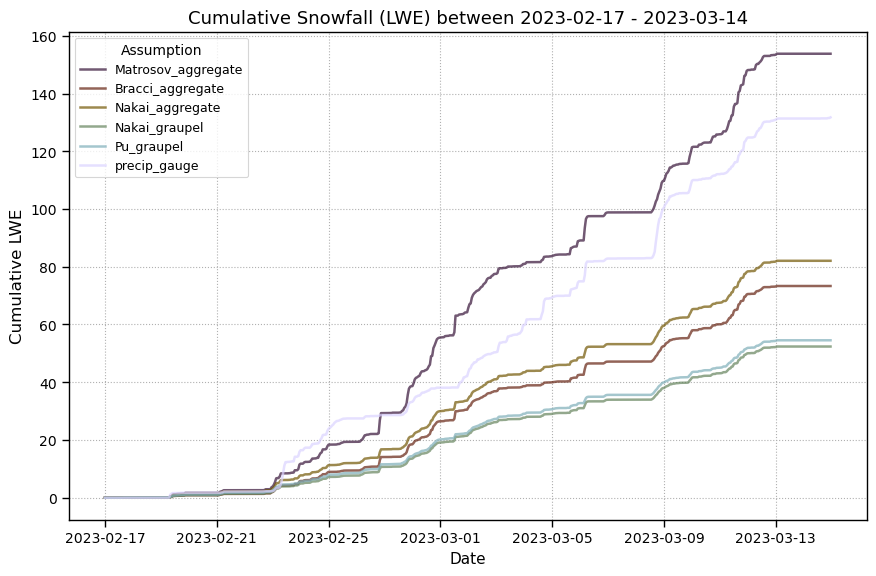

In [165]:
# Get cummulative LWE
df_cumsum = df_snowfall_rate.loc["2023-02-17":].cumsum()

# set up figure
fig, ax = plt.subplots(figsize=(9,6))

# Get glasgow colors
n_lines = df_cumsum.shape[1] if df_cumsum.ndim > 1 else 1
colors = cm.glasgow(np.linspace(0,1,n_lines))

# Plot each column in colors
if df_cumsum.ndim > 1:
    for i, col in enumerate(df_cumsum.columns):
        ax.plot(df_cumsum.index, df_cumsum[col], color=colors[i], label=col, linewidth=1.8, alpha=0.7)
    ax.legend(title="Assumption", fontsize=9, title_fontsize=10, loc='upper left')
else: 
    ax.plot(df_cumsum.index, df_cumsum, color=colors[0], linewidth=1.8, alpha=0.7)
    
# Styling
ax.set_ylabel("Cumulative LWE", fontsize=12)
ax.set_xlabel("Date", fontsize=11)
ax.grid(True, linestyle=':')
ax.set_title("Cumulative Snowfall (LWE) between 2023-02-17 - 2023-03-14", fontsize=13)
ax.tick_params(axis='both', labelsize=10)
plt.tight_layout()

figname = f"snowfall_rate/cumsum_literature_values.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [166]:
# Example: ranges based on literature or uncertainty bounds
a_vals = np.linspace(50, 100, 6)       # e.g. [50, 55, 60, 65, 70]
b_vals = np.linspace(1.1, 1.6, 6)     # e.g. [1.1, 1.15, 1.2, 1.25, 1.3]

In [167]:
# Create meshgrid of all (a, b) combinations
a_grid, b_grid = np.meshgrid(a_vals, b_vals, indexing='ij')  # shape: (5, 5)

In [191]:
# Broadcast Ze​ to match shape of ensemble
ze_surface = 10 ** (dsx['Ze'].isel(range=3) /10)
# Prepare empty array to hold ensemble output
S_ensemble = np.empty((len(a_vals), len(b_vals), len(ze_surface.time)))

# Compute snowfall rate for each (a, b) pair
for i, a in enumerate(a_vals):
    for j, b in enumerate(b_vals):
        S_ensemble[i, j, :] = (ze_surface / a) ** (1 / b)
        
# Convert to xarray DataArray for easy analysis

S_da = xr.DataArray(
    data = S_ensemble,
    dims = ['a', 'b', 'time'],
    coords = {
        'a': a_vals,
        'b': b_vals,
        'time': ze_surface.time
    },
    name='S_ensemble'
)

# Resample to hourly snowfall accumulations:

S_hourly = (S_da / 60).sel(time=slice("2023-02-17", "2023-03-17")).resample(time='1H').sum()   # mm/h -> mm per hour

In [192]:
from imports import (ListedColormap) 

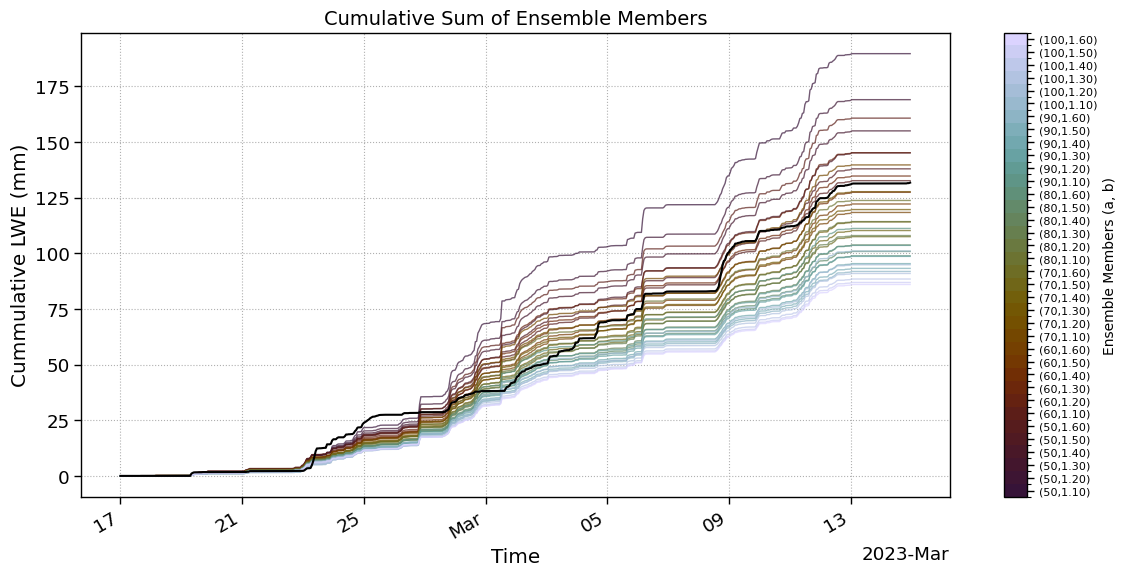

In [193]:
# Extract time-sliced and cumulative sum
S = S_hourly.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))

# Plot each ensemble member with a unique color
# i = 0
# for a_idx in range(n_a):
#     for b_idx in range(n_b):
#         S_member = S.isel(a=a_idx, b=b_idx)
#         S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
#         i += 1
for i, (a, b) in enumerate(labels):
    S_member = S.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
df_snowfall_rate['precip_gauge'].loc["2023-02-17":].cumsum().plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

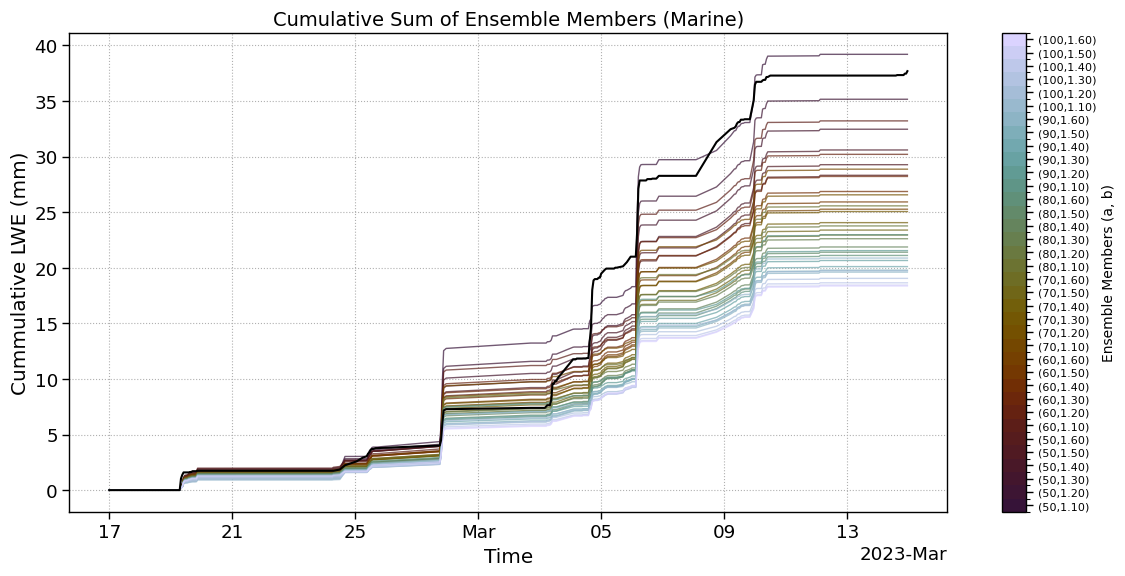

In [201]:
valid_times = dsx['precipitation_marine'].sel(time=slice("2023-02-17", "2023-03-17")).dropna('time').time
S_hourly_filtered = S_hourly.sel(time=valid_times)
S_hourly_filtered = S_hourly_filtered.cumsum(dim='time')

s_gauge_filtered = dsx['precipitation_marine'].sel(time=valid_times)
s_gauge_filtered = s_gauge_filtered.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))


for i, (a, b) in enumerate(labels):
    S_member = S_hourly_filtered.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
s_gauge_filtered.plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members (Marine)", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble_marine.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

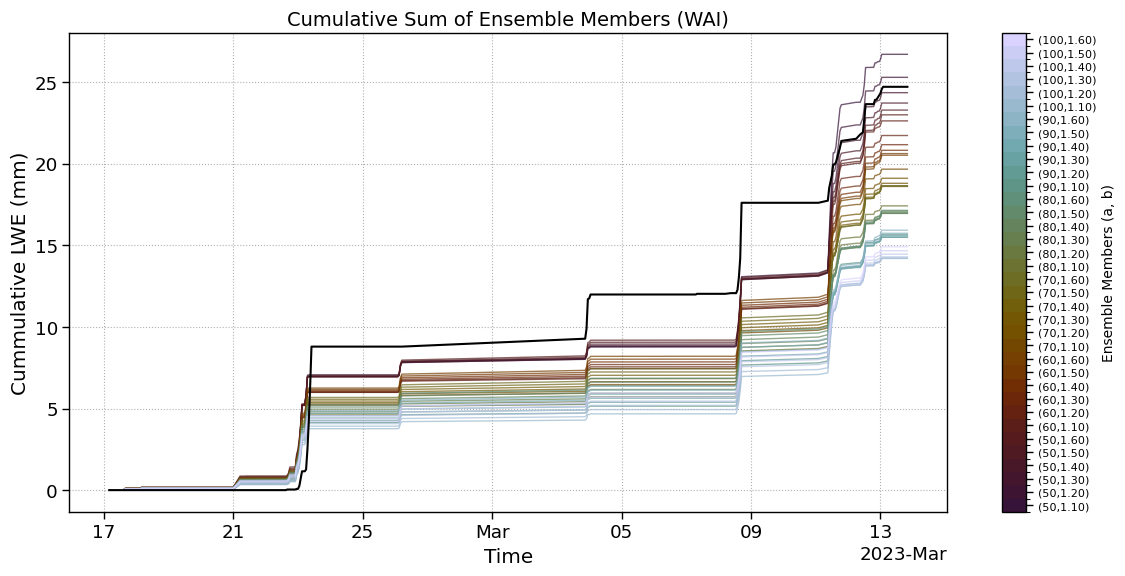

In [202]:
valid_times = dsx['precipitation_wai'].sel(time=slice("2023-02-17", "2023-03-17")).dropna('time').time
S_hourly_filtered = S_hourly.sel(time=valid_times)
S_hourly_filtered = S_hourly_filtered.cumsum(dim='time')

s_gauge_filtered = dsx['precipitation_wai'].sel(time=valid_times)
s_gauge_filtered = s_gauge_filtered.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))


for i, (a, b) in enumerate(labels):
    S_member = S_hourly_filtered.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
s_gauge_filtered.plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members (WAI)", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble_wai.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

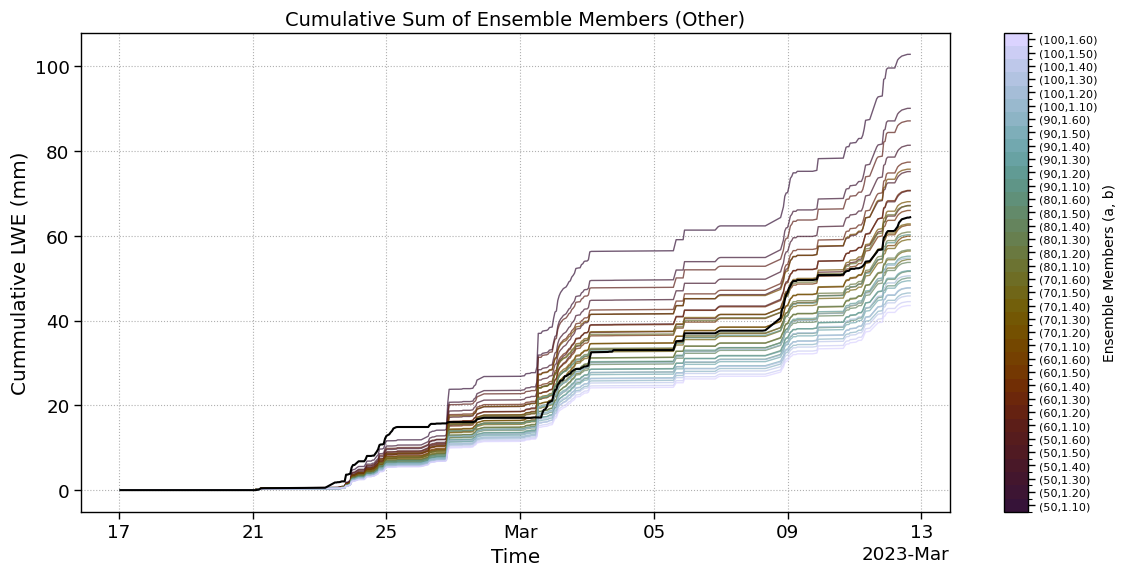

In [203]:
valid_times = dsx['precipitation_other'].sel(time=slice("2023-02-17", "2023-03-17")).dropna('time').time
S_hourly_filtered = S_hourly.sel(time=valid_times)
S_hourly_filtered = S_hourly_filtered.cumsum(dim='time')

s_gauge_filtered = dsx['precipitation_other'].sel(time=valid_times)
s_gauge_filtered = s_gauge_filtered.cumsum(dim='time')

# Get total number of ensemble members
a_vals = S.a.values
b_vals = S.b.values
n_a = S.sizes['a']
n_b = S.sizes['b']

# (a,b) label list
labels = [(a, b) for a in a_vals for b in b_vals]
n_members = n_a * n_b


# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Get glasgow colormap
cmap = cm.glasgow
colors = cmap(np.linspace(0, 1, n_members))


for i, (a, b) in enumerate(labels):
    S_member = S_hourly_filtered.sel(a=a, b=b)
    S_member.plot(ax=ax, color=colors[i], alpha=0.7, linewidth=1, add_legend=False)
s_gauge_filtered.plot(ax=ax, color='k', linewidth=1.5, )

cmap_discrete = ListedColormap(colors)
bounds = np.arange(n_members +1) - 0.5
norm = fct.BoundaryNorm(bounds, cmap_discrete.N)

sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm)
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(n_members), spacing='proportional', orientation='vertical')

# Set tick labels to (a,b)
cbar.set_ticklabels([f'({a:.0f},{b:.2f})' for (a, b) in labels])
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Ensemble Members (a, b)", fontsize=10)

# # Optional: Colorbar with index
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=n_members-1))
# cbar = plt.colorbar(sm, ax=ax, label='Ensemble Member Index')

# Prettify the plot
ax.set_title("Cumulative Sum of Ensemble Members (Other)", fontsize=14)
ax.set_ylabel("Cummulative LWE (mm)")
ax.grid(True, linestyle=':')
ax.set_xlabel("Time")
plt.tight_layout()

figname = f"snowfall_rate/cumsum_ensemble_other.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

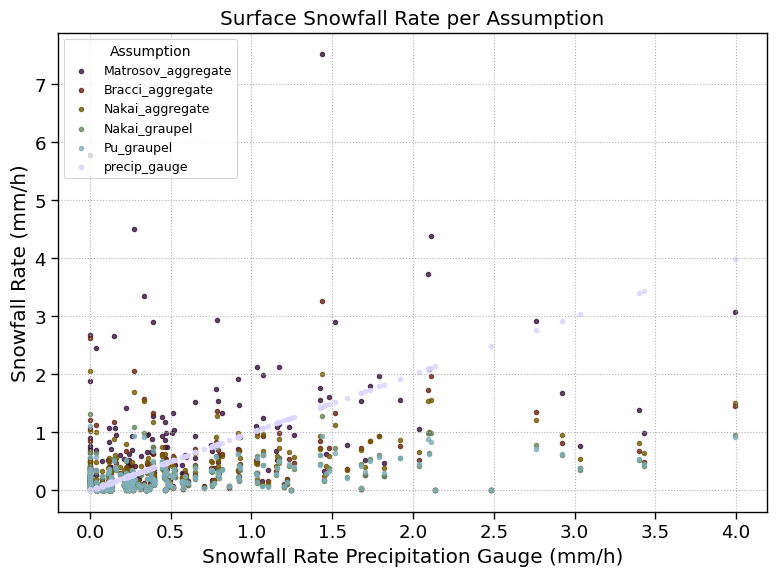

In [137]:
# Assume surface is the 3. lowest range gate
fig, ax = plt.subplots(figsize=(8,6), )
# Get glasgow colors
n_lines = df_snowfall_rate.shape[1] if df_snowfall_rate.ndim > 1 else 1
colors = cm.glasgow(np.linspace(0,1,n_lines))

if df_snowfall_rate.ndim > 1:
    for i, col in enumerate(df_snowfall_rate.columns):
        ax.scatter(df_snowfall_rate['precip_gauge'], df_snowfall_rate[col], color=colors[i], label=col, alpha=0.8, s=10)
    ax.legend(title="Assumption", fontsize=9, title_fontsize=10, loc='upper left')
else: 
    ax.scatter(df_snowfall_rate['precip_gauge'], df_snowfall_rate, color=colors[0], alpha=0.8, s=10)

# Labels, legend, grid
ax.set_ylabel("Snowfall Rate (mm/h)")
ax.set_xlabel("Snowfall Rate Precipitation Gauge (mm/h)")
ax.grid(True, ls=':')
ax.set_title("Surface Snowfall Rate per Assumption")

plt.tight_layout()

### Fit $Ze=a \cdot S ^b$

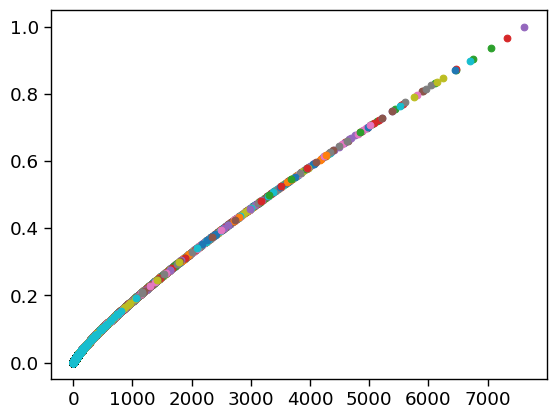

In [ ]:
for i in dsx['range'].values:
    plt.scatter(dsx['Z'].sel(range=i), snowfall_rate.sel(range=i))